##  Pasul 1: Activarea Uneltelor de Inginerie
### Ce fac aceste unelte?
* **TensorFlow:** Este "motorul" de Inteligență Artificială creat de Google.
* **OpenCV (cv2):** Reprezintă "ochii" calculatorului. Transformă imaginile în date pe care AI-ul le poate înțelege.
* **NumPy:** Se ocupă de "matematica grea" (calcule cu matrici).
* **Matplotlib:** Ne ajută să desenăm grafice și să vizualizăm rezultatele.



In [2]:
import os                   # Pentru a lucra cu foldere și fișiere
import cv2
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from google.colab import files # Modul special pentru a încărca fișiere în Colab

print("Toate uneltele au fost activate! Putem începe .")

Toate uneltele au fost activate! Putem începe .


## Etapa 2: Importul Datelor de Antrenament (Dataset-ul)

Voi aveți pregătită o arhivă (`.zip`) care conține cateva exemple de litere scrise de mână, sortate în foldere:
* Folderul **A**
* Folderul **C**
* Folderul **D**



In [3]:

print("⬇ Te rog să încarci arhiva ZIP cu imaginile (dataset_vizual.zip)...")

# Deschide fereastra de upload
fisiere_incarcate = files.upload()

# Luăm numele arhivei (oricare ar fi el)
nume_arhiva = list(fisiere_incarcate.keys())[0]

print(f"\n Dezarhivăm pachetul '{nume_arhiva}'...")
# Dezarhivăm în folderul 'date_elevi'
!unzip -q {nume_arhiva} -d date_elevi

print(" Gata! Avem dosarele cu litere pregătite.")

⬇ Te rog să încarci arhiva ZIP cu imaginile (dataset_vizual.zip)...


Saving dataset_vizual.zip to dataset_vizual.zip

 Dezarhivăm pachetul 'dataset_vizual.zip'...
 Gata! Avem dosarele cu litere pregătite.


### Etapa 3: Transformarea Imaginilor în Matematică (Preprocessing)


Codul de mai jos va face **3 operații critice** pentru fiecare imagine găsită:

1.  **Conversia în Alb-Negru (Grayscale)**
    

2.  **Standardizarea (Resize la 28x28 pixeli):**
    * Indiferent cum poza noastră este făcută, noi o micșorăm la 28x28 pixeli.
    * **De ce?** Rețeaua neurală are un număr fix de "intrări". Trebuie să primească mereu aceeași dimensiune.

3.  **Normalizarea (Împărțirea la 255):**
    * Un pixel are o valoare între **0** (negru) și **255** (alb).
    * Noi împărțim totul la 255 pentru a obține valori între **0 și 1**.
    * *Matematica din spatele AI-ului funcționează mult mai rapid cu numere mici (subunitare).*


 Căutăm folderele cu date...
 Am găsit datele în folderul: 'date_elevi'
 Începem citirea și transformarea imaginilor...

 Procesăm folderul 'A': Am găsit 20 imagini.
 Procesăm folderul 'C': Am găsit 20 imagini.
 Procesăm folderul 'D': Am găsit 20 imagini.

 TOTAL: Am transformat 60 imagini în matematică pură!
Dimensiunea setului de date: (60, 28, 28)


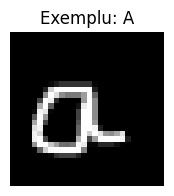

In [4]:

lista_imagini = []
lista_etichete = []
categoriile_litere = ["A", "C", "D"]

print(" Căutăm folderele cu date...")

# Această bucată de cod caută singură unde sunt dosarele A, C, D
cale_reala = None
for root, dirs, files in os.walk("date_elevi"):
  #################################################################
    # Verificăm dacă am găsit locul unde stau toate cele 3 litere
   if "A" in dirs and "C" in dirs and "D" in dirs:
        cale_reala = root
        print(f" Am găsit datele în folderul: '{cale_reala}'")
        break
####################################################################
if cale_reala is None:
    print(" EROARE: Nu găsesc folderele A, C, D! Verifică arhiva ZIP.")
else:
    print(" Începem citirea și transformarea imaginilor...\n")

    # Trecem prin fiecare folder găsit
    for numar_eticheta, nume_folder in enumerate(categoriile_litere):
        cale_folder_curent = os.path.join(cale_reala, nume_folder)

        fisiere_gasite = os.listdir(cale_folder_curent)
        # Filtrăm doar fișierele de imagine
        fisiere_gasite = [f for f in fisiere_gasite if f.endswith(('.png', '.jpg', '.jpeg'))]

        print(f" Procesăm folderul '{nume_folder}': Am găsit {len(fisiere_gasite)} imagini.")

        for nume_poza in fisiere_gasite:
            cale_completa = os.path.join(cale_folder_curent, nume_poza)

            # 1. Citim poza alb-negru
            imagine = cv2.imread(cale_completa, cv2.IMREAD_GRAYSCALE)

            if imagine is not None:
                # 2. Redimensionăm la 28x28
                imagine = cv2.resize(imagine, (28, 28))

                # 3. Adăugăm în listă
                lista_imagini.append(imagine)
                lista_etichete.append(numar_eticheta)

    # Transformăm în format NumPy
    X_date = np.array(lista_imagini)
    y_etichete = np.array(lista_etichete)

    # Normalizare (0-1)
    if len(X_date) > 0:
        X_date = X_date / 255.0
        print(f"\n TOTAL: Am transformat {len(X_date)} imagini în matematică pură!")
        print(f"Dimensiunea setului de date: {X_date.shape}")

        # Vizualizare rapidă ca să fim siguri
        plt.figure(figsize=(2,2))
        plt.imshow(X_date[0], cmap='gray')
        plt.title(f"Exemplu: {categoriile_litere[y_etichete[0]]}")
        plt.axis('off')
        plt.show()
    else:
        print(" Nu am reușit să încarc nicio imagine. Verifică dacă folderul e gol.")

###  Etapa 4: Arhitectura Rețelei Neuronale (Construirea "Creierului")

#### Structura Modelului Nostru:

1.  **Stratul de Intrare (Input - Flatten):**
    * Imaginea voastră este un pătrat de 28x28 pixeli (o matrice 2D).
    * Acest strat "desface" pătratul și pune toți pixelii într-un singur șir lung de 784 de numere

2.  **Stratul Ascuns (Hidden Layer - Dense):**
    * Aici avem **128 de neuroni artificiali**.
    * Ei sunt interconectați și caută modele matematice (linii, curbe, colțuri).
    * **Funcția `relu`:** Este ca un întrerupător. Dacă un neuron găsește ceva relevant, se activează; dacă nu, stă stins.

3.  **Stratul de Ieșire (Output Layer):**
    * Avem fix **3 neuroni**, pentru că avem 3 posibilități: **A, C, sau D**.
    * **Funcția `softmax`:** Transformă rezultatul final în **probabilități**. (Ex: "Sunt 90% sigur că e A, 9% că e D și 1% că e C").

---

* **Optimizer (Adam):** Algoritmul care ajustează neuronii pentru a reduce greșelile.
* **Loss:** Funcția care calculează cât de mult a greșit modelul la fiecare pas.

In [5]:
print(" Construim rețeaua neuronală...")

model_inteligenta = tf.keras.models.Sequential([
    # STRATUL 1: "Ochii" (Input)
    # Transformăm matricea 2D (28x28) într-un șir lung de numere (vector)
    tf.keras.layers.Flatten(input_shape=(28, 28)),

    # STRATUL 2: "Neuronii" (Hidden Layer)
    # 128 de neuroni care fac calcule matematice complexe
    # 'relu' este funcția care le spune când să se activeze
    tf.keras.layers.Dense(128, activation='relu'),

    # STRATUL 3: "Decizia" (Output Layer)
    # Avem 3 neuroni pentru cele 3 litere (A, C, D)
    # 'softmax' transformă numerele în probabilități (procente)
    tf.keras.layers.Dense(3, activation='softmax')
])

model_inteligenta.compile(
    optimizer='adam',  # "Profesorul" care ajustează neuronii (standardul în industrie)
    loss='sparse_categorical_crossentropy', # Cum măsurăm eroarea (nota mică)
    metrics=['accuracy'] # Ce ne interesează: Precizia (nota mare)
)

print(" Modelul a fost construit! Iată structura lui:")
model_inteligenta.summary()

 Construim rețeaua neuronală...


/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


 Modelul a fost construit! Iată structura lui:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 100,867 (394.01 KB)

 Trainable params: 100,867 (394.01 KB)

 Non-trainable params: 0 (0.00 B)

### Etapa 5: Antrenamentul (Learning Phase)


Modelul va face următorii pași, în mod repetat:
1.  Ia o imagine și "ghicește" ce literă este.
2.  Compară răspunsul lui cu eticheta corectă
3.  Calculează cât de mult a greșit (**Loss**).
4.  Își ajustează neuronii pentru a greși mai puțin data viitoare.

####Ce sunt "Epochs" (Epocile)?
Am setat `epochs=50`. Asta înseamnă că AI-ul va trece prin **toate** imaginile noastre de **50 de ori**.
* **La început (Epoca 1):** AI-ul ghicește aproape la întâmplare. Eroarea este mare.
* **La final (Epoca 50):** AI-ul a învățat tiparele. Eroarea ar trebui să fie aproape de 0.


In [7]:

print(" Începem antrenamentul! Priviți cum scade eroarea (loss)...")

istoric = model_inteligenta.fit(X_date, y_etichete, epochs=50)

print("\n Antrenament finalizat! Creierul artificial este gata.")

 Începem antrenamentul! Priviți cum scade eroarea (loss)...
Epoch 1/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 598ms/step - accuracy: 0.3799 - loss: 1.1059
Epoch 2/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.7076 - loss: 0.8132
Epoch 3/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.9458 - loss: 0.6177
Epoch 4/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.9778 - loss: 0.4782
Epoch 5/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.9569 - loss: 0.3881
Epoch 6/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.9785 - loss: 0.3018
Epoch 7/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 1.0000 - loss: 0.2353
Epoch 8/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 1.0000 - loss: 0.1895
Epoch 9/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 1.0000 - loss: 0.1448
Epoch 10/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 1.0000 - loss: 0.1302
Epoch 11/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 1.0000 - loss: 0.1046
Epoch 12/50
2/2 ━━━━━━━━

###Etapa 6: Vizualizarea Performanței (Raportul Grafic)

Vom genera două grafice esențiale:
1.  **Graficul Preciziei (Stânga - Verde):** Arată cât de deștept a devenit modelul. Vrem să vedem o linie care urcă spre 1.0 (100%).
2.  **Graficul Erorii (Dreapta - Roșu):** Arată cât de confuz este modelul. Vrem să vedem o linie care "se prăbușește" spre 0.


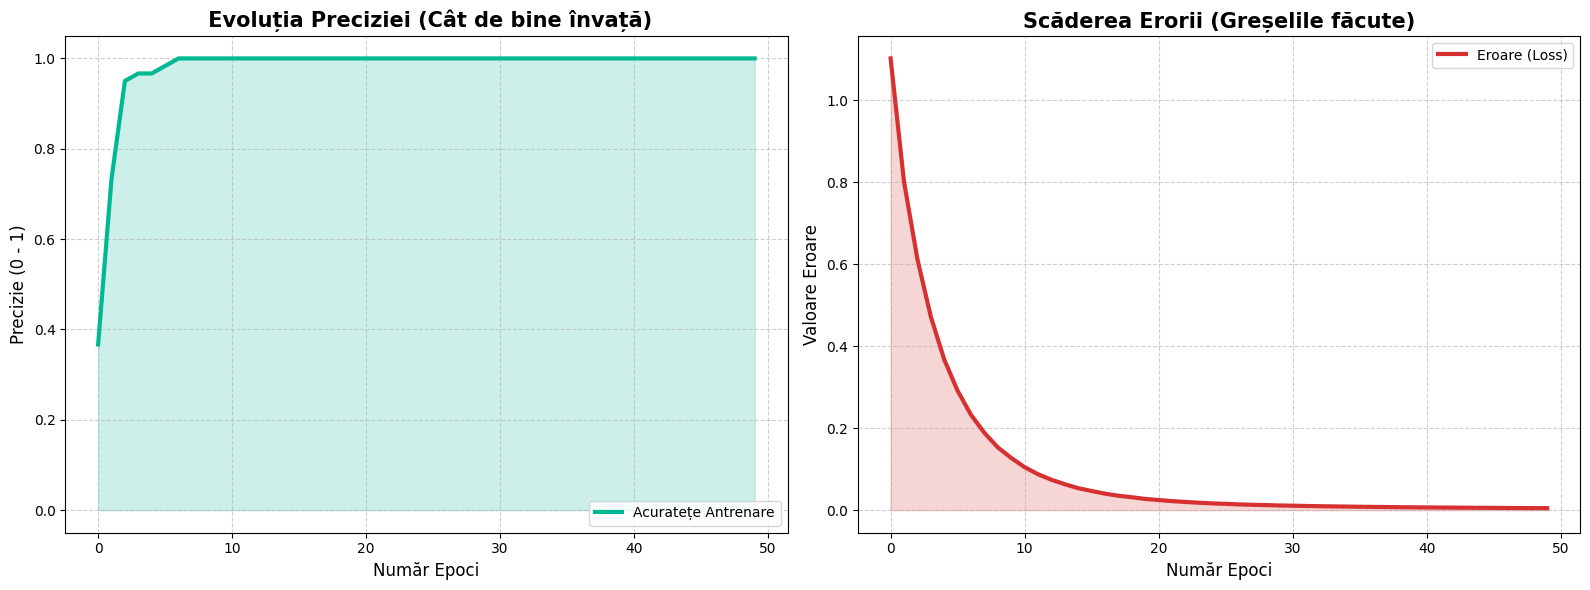

In [8]:
import matplotlib.pyplot as plt

# Extragem datele din istoric
acc = istoric.history['accuracy']
loss = istoric.history['loss']
epochs_range = range(len(acc))

# Setăm dimensiunea imaginii (Latime x Inaltime)
plt.figure(figsize=(16, 6))

# --- GRAFICUL 1: PRECIZIA (Stânga) ---
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Acuratețe Antrenare', color='#00b894', linewidth=3)
plt.fill_between(epochs_range, acc, color='#00b894', alpha=0.2)
plt.title(' Evoluția Preciziei (Cât de bine învață)', fontsize=15, fontweight='bold')
plt.xlabel('Număr Epoci', fontsize=12)
plt.ylabel('Precizie (0 - 1)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='lower right')

# --- GRAFICUL 2: EROAREA (Dreapta) ---
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Eroare (Loss)', color='#d63031', linewidth=3)
plt.fill_between(epochs_range, loss, color='#d63031', alpha=0.2)
plt.title('Scăderea Erorii (Greșelile făcute)', fontsize=15, fontweight='bold')
plt.xlabel('Număr Epoci', fontsize=12)
plt.ylabel('Valoare Eroare', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='upper right')

plt.tight_layout() # Aranjează graficele să nu se suprapună
plt.show()


### Etapa 7: Crearea Interfeței de Desen (Input System)

Până acum am lucrat cu imagini salvate în fișiere. Dar adevărata provocare pentru un inginer este să facă sistemul să funcționeze în **timp real**.

Pentru asta, vom construi o mică aplicație web direct aici, în notebook.
Vom folosi un mix de tehnologii:
1.  **HTML & JavaScript:** Pentru a crea o "tablă" neagră pe care puteți desena cu mouse-ul.
2.  **Python:** Pentru a prelua desenul vostru și a-l pregăti pentru Inteligența Artificială.

#### Ce se întâmplă în spate?
Când apăsați "GHICEȘTE":
* Desenul este convertit într-un șir de cod (Base64).
* Este trimis către Python.
* Python îl micșorează rapid la **28x28 pixeli** (exact cum a învățat modelul la antrenament).
* Ecranul se curăță pentru a afișa rezultatul.

In [9]:
from IPython.display import display, HTML, clear_output
from google.colab.output import eval_js
from base64 import b64decode
import time

# Codul HTML/JS pentru tabla de desen (Varianta Stabilă)
CANVAS_DEMO = """
<canvas id="canvas_demo" width="200" height="200" style="border: 2px solid #4CAF50; background-color: black; cursor: crosshair;"></canvas>
<br>
<button id="btn_demo" style="font-size: 16px; margin-top: 10px; padding: 10px 20px; background-color: #4CAF50; color: white; border: none; border-radius: 5px;">🔮 GHICEȘTE !</button>
<button onclick="sterge_demo()" style="font-size: 16px; margin-top: 10px; padding: 10px 20px; background-color: #f44336; color: white; border: none; border-radius: 5px;">Șterge</button>
<script>
    var canvas = document.getElementById('canvas_demo');
    var ctx = canvas.getContext('2d');
    ctx.lineWidth = 14; // Grosimea creionului
    ctx.strokeStyle = 'white';
    var isDrawing = false;

    canvas.onmousedown = function(e) { isDrawing = true; ctx.beginPath(); ctx.moveTo(e.offsetX, e.offsetY); };
    canvas.onmousemove = function(e) { if (isDrawing) { ctx.lineTo(e.offsetX, e.offsetY); ctx.stroke(); } };
    canvas.onmouseup = function() { isDrawing = false; };

    function sterge_demo() { ctx.fillStyle = "black"; ctx.fillRect(0, 0, canvas.width, canvas.height); }

    var btn = document.getElementById('btn_demo');
    btn.onclick = function() {
        var data = canvas.toDataURL('image/png');
        window.resolve_demo(data);
    }
</script>
"""

def deseneaza_pentru_test():
  display(HTML("<h3>Desenează o literă (a, c sau d) aici:</h3>"))
  display(HTML(CANVAS_DEMO))

  # Așteptăm desenul
  data = eval_js("new Promise((resolve, reject) => { window.resolve_demo = resolve; })")

  # Procesăm imaginea
  binary = b64decode(data.split(',')[1])
  img_array = np.frombuffer(binary, dtype=np.uint8)
  img = cv2.imdecode(img_array, cv2.IMREAD_GRAYSCALE)

  # Redimensionăm la 28x28
  img_resized = cv2.resize(img, (28, 28), interpolation=cv2.INTER_AREA)

  # Curățăm ecranul
  clear_output(wait=True)
  return img_resized

print(" Interfața de testare este activă!")

 Interfața de testare este activă!


### Etapa 8: Momentul Adevărului (Live Demo)

**Rulați celula, desenați pe tabla neagră și apăsați butonul GHICEȘTE!**

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step

 AI-ul spune:  A
 Încredere:    99.94%


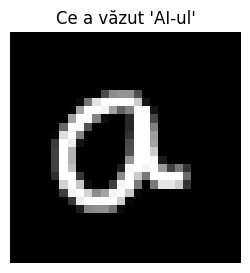


 Analiza detaliată (Ce s-a petrecut în 'mintea' lui):
Probabilitate A: 99.94%
Probabilitate C: 0.01%
Probabilitate D: 0.05%


In [26]:
# 1. Desenăm
imagine_test = deseneaza_pentru_test()

# 2. Pregătim imaginea pentru AI
# Trebuie să fie (1, 28, 28) și valori între 0-1
imagine_procesata = imagine_test / 255.0
imagine_batch = np.expand_dims(imagine_procesata, axis=0)

# 3. AI-ul face predicția
predictii = model_inteligenta.predict(imagine_batch)

# 4. Interpretăm rezultatul
# Argmax ne zice care neuron e cel mai activ (0, 1 sau 2)
index_castigator = np.argmax(predictii)
procent_incredere = np.max(predictii) * 100

dictionar = {0: "A", 1: "C", 2: "D"}
litera_ghicita = dictionar[index_castigator]

# --- AFIȘAREA REZULTATULUI ---
print("\n" + "="*40)
print(f" AI-ul spune:  {litera_ghicita}")
print(f" Încredere:    {procent_incredere:.2f}%")
print("="*40)

# Afișăm și ce a văzut AI-ul
plt.figure(figsize=(3,3))
plt.imshow(imagine_test, cmap='gray')
plt.title("Ce a văzut 'AI-ul'")
plt.axis('off')
plt.show()

# Afișăm detaliile tehnice (procentele pentru fiecare literă)
print("\n Analiza detaliată (Ce s-a petrecut în 'mintea' lui):")
print(f"Probabilitate A: {predictii[0][0]*100:.2f}%")
print(f"Probabilitate C: {predictii[0][1]*100:.2f}%")
print(f"Probabilitate D: {predictii[0][2]*100:.2f}%")